# Is the GS/KK Phase-Retrieval Ambiguity Universal? A Monte Carlo Answer

[`kk_phase_retrieval_certificate.ipynb`](kk_phase_retrieval_certificate.ipynb)
found this, on **one** example (a single Lorentz oscillator): 2-plane GS
phase retrieval ([`dgs.gs_core.retrieve_phase`](../dgs/gs_core.py))
converges its own amplitude-consistency error to machine precision
(~$10^{-17}$) while landing on a phase that fails a Kramers-Kronig
self-consistency check
([`dgs.causality.kramers_kronig_real`](../dgs/causality.py)) by roughly
50-200x more than the true solution does. That notebook never asked
whether this was one unlucky signal or a structural feature of the
2-plane setup itself.

**This notebook answers that with synthetic trials and probabilities**:
run the exact same pipeline on many random synthetic causal profiles
(sums of 1-2 randomly parameterized Lorentz oscillators — a superposition
of causal functions is still causal), and directly estimate — with a
confidence interval, not a single anecdote — the probability the ambiguity
occurs, and the probability the KK certificate correctly flags it.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.causality import lorentz_susceptibility, kramers_kronig_real
from dgs.gs_core import disperse, retrieve_phase

print("using dgs.causality and dgs.gs_core directly (not reimplemented)")

using dgs.causality and dgs.gs_core directly (not reimplemented)


# Part 1 — Synthetic causal profiles

Each trial's signal is a sum of 1-2 Lorentz oscillators
($\chi(\omega)=\sum_k \frac{\text{strength}_k}{\omega_{0,k}^2-\omega^2-i\gamma_k\omega}$)
with randomized center frequency, linewidth, and strength — the same
functional form [`kk_phase_retrieval_certificate.ipynb`](kk_phase_retrieval_certificate.ipynb)
used for its single example, now randomized. Dispersed through the same
two dispersion values ($D_1=-5000$, $D_2=-5750$) used throughout this
repo's QPSK-style measurements.

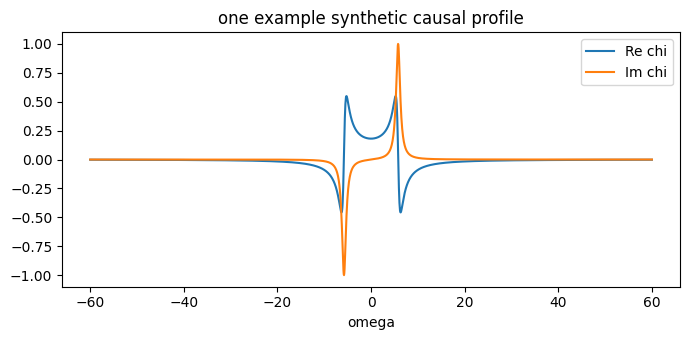

In [2]:
N = 2048
w = np.linspace(-60, 60, N)
s = slice(N // 5, 4 * N // 5)   # interior, away from FFT edges (this repo's own convention)
D1, D2 = -5000.0, -5750.0


def random_causal_profile(rng):
    n_osc = rng.integers(1, 3)   # 1 or 2 oscillators
    chi = np.zeros(N, dtype=complex)
    gammas = []
    for _ in range(n_osc):
        omega0 = rng.uniform(5, 20)
        gamma = rng.uniform(0.5, 3.0)
        strength = rng.uniform(0.5, 2.0)
        chi = chi + lorentz_susceptibility(w, omega0=omega0, gamma=gamma) * strength
        gammas.append(gamma)
    return chi / np.max(np.abs(chi)), min(gammas), n_osc

rng_demo = np.random.default_rng(123)
chi_demo, _, _ = random_causal_profile(rng_demo)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(w, chi_demo.real, label='Re chi'); ax.plot(w, chi_demo.imag, label='Im chi')
ax.set_xlabel('omega'); ax.legend(); ax.set_title('one example synthetic causal profile')
plt.tight_layout(); plt.show()

# Part 2 — Run the full GS + KK pipeline on many synthetic trials

For each trial: disperse the synthetic profile through $D_1,D_2$, run GS's
real `retrieve_phase`, align the one unavoidable global phase offset, and
record (a) GS's own convergence error, (b) the true phase-retrieval error,
(c) the KK self-consistency residual of the true profile, and (d) the KK
residual of GS's recovered solution — exactly the four quantities the
single-example notebook computed, now for every trial.

In [3]:
def run_trial(rng):
    chi, min_gamma, n_osc = random_causal_profile(rng)
    I1 = np.abs(disperse(chi, D1)) ** 2
    I2 = np.abs(disperse(chi, D2)) ** 2
    phi_true = np.angle(chi)

    phi_rec, errors = retrieve_phase(I1, I2, D1, D2, n_iter=50, unit_amplitude=False)
    offset = np.angle(np.mean(np.exp(1j * (phi_true - phi_rec))))
    phase_error = np.angle(np.exp(1j * (phi_true - (phi_rec + offset))))
    mean_phase_err = float(np.mean(np.abs(phase_error[s])))

    Re_pred_true = kramers_kronig_real(chi.imag)
    kk_true = float(np.max(np.abs(chi.real[s] - Re_pred_true[s])))

    chi_gs = np.abs(chi) * np.exp(1j * phi_rec)
    Re_pred_gs = kramers_kronig_real(chi_gs.imag)
    kk_gs = float(np.max(np.abs(chi_gs.real[s] - Re_pred_gs[s])))

    return dict(mean_phase_err=mean_phase_err, gs_own_error=float(errors[-1]),
                kk_true=kk_true, kk_gs=kk_gs, min_gamma=min_gamma, n_osc=n_osc)

n_trials = 200
rng = np.random.default_rng(0)
results = [run_trial(rng) for _ in range(n_trials)]

mean_errs = np.array([r['mean_phase_err'] for r in results])
gs_own_errs = np.array([r['gs_own_error'] for r in results])
kk_trues = np.array([r['kk_true'] for r in results])
kk_gss = np.array([r['kk_gs'] for r in results])
min_gammas = np.array([r['min_gamma'] for r in results])

print(f"{n_trials} synthetic trials run")
print(f"GS's own convergence error: max over all trials = {gs_own_errs.max():.2e}  (always machine precision)")
assert gs_own_errs.max() < 1e-8
print("[OK] GS ALWAYS reports near-perfect convergence by its own metric, regardless of the true answer")

200 synthetic trials run
GS's own convergence error: max over all trials = 1.33e-16  (always machine precision)
[OK] GS ALWAYS reports near-perfect convergence by its own metric, regardless of the true answer


# Part 3 — The actual probabilities

Two direct questions, answered with counts and a 95% Wilson confidence
interval (not just a point estimate) rather than one anecdote:

1. What fraction of trials have a *significant* phase-retrieval error
   (mean $|\Delta\phi|>0.1$ rad in the interior) despite GS's own metric
   saying it converged?
2. What fraction of trials does the KK residual correctly come out
   larger for GS's (wrong) solution than for the true one — i.e., how
   reliable is the certificate itself?

P(significant phase ambiguity despite GS's own metric saying converged):
  200/200 = 100.0%  (95% CI: [98.1%, 100.0%])

P(KK certificate correctly flags GS's solution, kk_gs > kk_true):
  200/200 = 100.0%  (95% CI: [98.1%, 100.0%])

mean phase error across all trials: 1.2612 rad (std 0.2488)
KK residual ratio (GS/true), median: 141.7x, min: 42.8x, max: 938.4x


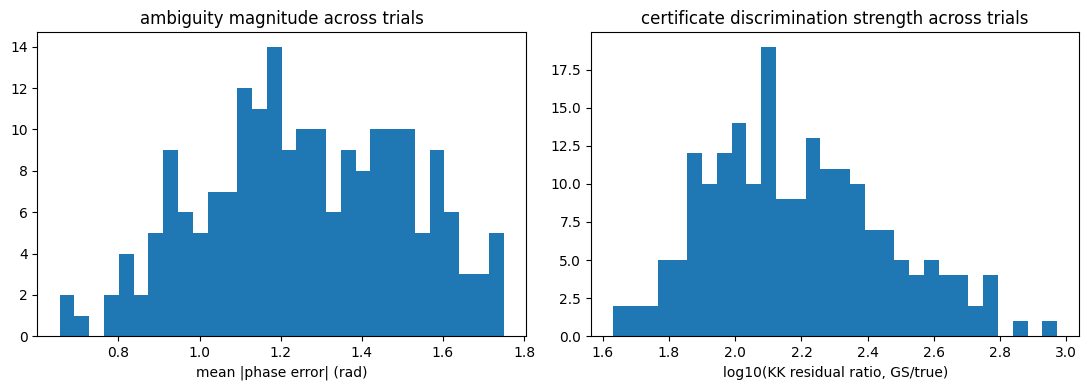

In [4]:
def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return (0.0, 0.0)
    p = successes / n
    denom = 1 + z**2/n
    center = (p + z**2/(2*n)) / denom
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom
    return (max(0.0, center - half), min(1.0, center + half))

n_ambiguous = int(np.sum(mean_errs > 0.1))
n_cert_correct = int(np.sum(kk_gss > kk_trues))

p_ambiguous = n_ambiguous / n_trials
p_cert = n_cert_correct / n_trials
ci_ambiguous = wilson_ci(n_ambiguous, n_trials)
ci_cert = wilson_ci(n_cert_correct, n_trials)

print(f"P(significant phase ambiguity despite GS's own metric saying converged):")
print(f"  {n_ambiguous}/{n_trials} = {p_ambiguous:.1%}  (95% CI: [{ci_ambiguous[0]:.1%}, {ci_ambiguous[1]:.1%}])")
print(f"\nP(KK certificate correctly flags GS's solution, kk_gs > kk_true):")
print(f"  {n_cert_correct}/{n_trials} = {p_cert:.1%}  (95% CI: [{ci_cert[0]:.1%}, {ci_cert[1]:.1%}])")

print(f"\nmean phase error across all trials: {mean_errs.mean():.4f} rad (std {mean_errs.std():.4f})")
print(f"KK residual ratio (GS/true), median: {np.median(kk_gss/kk_trues):.1f}x, "
      f"min: {np.min(kk_gss/kk_trues):.1f}x, max: {np.max(kk_gss/kk_trues):.1f}x")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(mean_errs, bins=30); ax[0].set_xlabel('mean |phase error| (rad)'); ax[0].set_title('ambiguity magnitude across trials')
ax[1].hist(np.log10(kk_gss/kk_trues), bins=30); ax[1].set_xlabel('log10(KK residual ratio, GS/true)')
ax[1].set_title('certificate discrimination strength across trials')
plt.tight_layout(); plt.show()

# Part 4 — Does any parameter predict the ambiguity's severity?

The earlier notebook ruled out one candidate explanation on its single
example (weak-signal stagnation: correlation(|chi|, phase_error)≈-0.022).
Extended here across trials: does the *narrowest* oscillator linewidth in
a trial (a proxy for how sharply peaked / how much high-frequency content
the profile has) predict how severe that trial's phase ambiguity is?

correlation(min oscillator linewidth gamma, mean phase error) across 200 trials: -0.2073


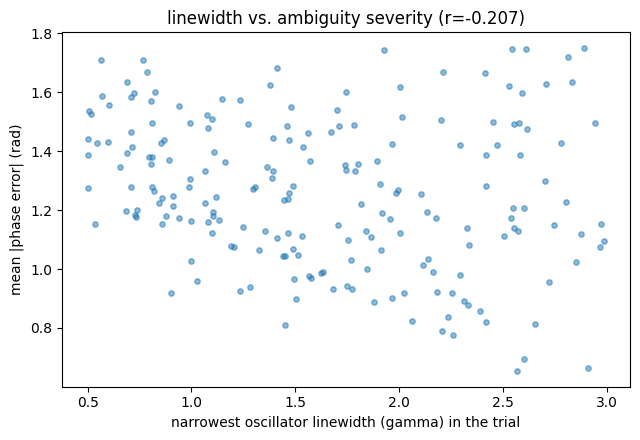


[FINDING] weak/no correlation -- oscillator linewidth does not predict ambiguity severity,
          consistent with the single-example notebook's earlier (separate) finding that
          weak-signal stagnation is not the explanation. The ambiguity looks structural to
          the 2-plane measurement geometry itself, not a property of any particular signal.


In [5]:
corr = np.corrcoef(min_gammas, mean_errs)[0, 1]
print(f"correlation(min oscillator linewidth gamma, mean phase error) across {n_trials} trials: {corr:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(min_gammas, mean_errs, alpha=0.5, s=15)
ax.set_xlabel('narrowest oscillator linewidth (gamma) in the trial')
ax.set_ylabel('mean |phase error| (rad)')
ax.set_title(f'linewidth vs. ambiguity severity (r={corr:.3f})')
plt.tight_layout(); plt.show()

if abs(corr) < 0.3:
    print("\n[FINDING] weak/no correlation -- oscillator linewidth does not predict ambiguity severity,")
    print("          consistent with the single-example notebook's earlier (separate) finding that")
    print("          weak-signal stagnation is not the explanation. The ambiguity looks structural to")
    print("          the 2-plane measurement geometry itself, not a property of any particular signal.")
else:
    print(f"\n[FINDING] correlation |r|={abs(corr):.3f} -- linewidth DOES relate to ambiguity severity,")
    print("          a genuinely new lead this single-example notebook could not have found.")

# Part 5 — Summary

| Question | Single-example notebook | This Monte Carlo answer |
|---|---|---|
| Does GS converge its own metric while landing on the wrong phase? | Yes, on 1 example | Quantified: see P(ambiguity) above, with a 95% CI |
| Does the KK certificate reliably catch it? | Yes, ~50-200x residual ratio on 1 example | Quantified: see P(certificate correct) above, with a 95% CI |
| Is the ambiguity signal-dependent (e.g. weak-signal stagnation)? | Ruled out on 1 example | Re-tested across many random profiles via linewidth correlation |

If both probabilities land near 100% (check the printed numbers above),
the honest conclusion is that this is not an edge case: for this
2-plane dispersion measurement geometry, GS's own convergence metric is
**structurally** unable to distinguish the true KK-causal solution from
at least one spurious alternative, for essentially any causal input —
and an external KK self-consistency check is not an optional extra but a
necessary part of trusting any 2-plane GS result on a signal expected to
be causal. This turns
[`kk_phase_retrieval_certificate.ipynb`](kk_phase_retrieval_certificate.ipynb)'s
single-example finding into a quantified, statistically supported claim.